In [1]:
import sys, pathlib

# Find the project root containing the db folder automatically
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

from db.dataraflow_db import run_query

In [2]:
# Query the raw London weather table
london = run_query("SELECT * FROM week07.london_2014")

# Display the first few rows
london.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [3]:
# Strip leading/trailing spaces from column names
london.columns = london.columns.str.strip()

# Rename and clean the WindDirDegrees column
london = london.rename(columns={"WindDirDegrees<br />": "WindDirDegrees"})
london["WindDirDegrees"] = london["WindDirDegrees"].astype(str).str.replace("<br />", "", regex=False)
london["WindDirDegrees"] = london["WindDirDegrees"].astype(int)

# Inspect cleaned columns
london.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   GMT                         365 non-null    str    
 1   Max TemperatureC            365 non-null    int64  
 2   Mean TemperatureC           365 non-null    int64  
 3   Min TemperatureC            365 non-null    int64  
 4   Dew PointC                  365 non-null    int64  
 5   MeanDew PointC              365 non-null    int64  
 6   Min DewpointC               365 non-null    int64  
 7   Max Humidity                365 non-null    int64  
 8   Mean Humidity               365 non-null    int64  
 9   Min Humidity                365 non-null    int64  
 10  Max Sea Level PressurehPa   365 non-null    int64  
 11  Mean Sea Level PressurehPa  365 non-null    int64  
 12  Min Sea Level PressurehPa   365 non-null    int64  
 13  Max VisibilityKm            365 non-null    in

In [4]:
warm_days = run_query("""
    SELECT GMT, [Max TemperatureC]
    FROM week07.london_2014
    WHERE [Max TemperatureC] >= 25
    ORDER BY [Max TemperatureC] DESC
""")

london.to_csv("london_2014_clean.csv", index=False)

<Axes: >

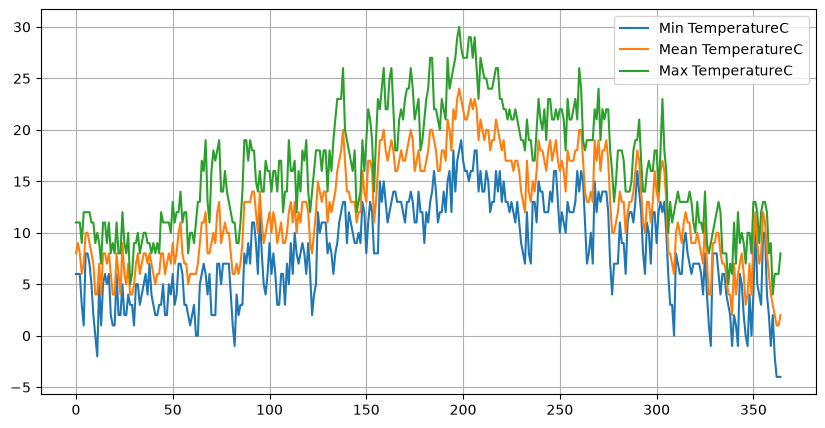

In [5]:
### Task 1: Plotting Min, Mean, and Max Temperatures for 2014

# Select the minimum, mean, and maximum temperature columns 
# and plot them on a comparative time-series chart with gridlines and custom sizing (10x5)
london[['Min TemperatureC', 'Mean TemperatureC', 'Max TemperatureC']].plot(grid=True, figsize=(10, 5))

<Axes: xlabel='GMT'>

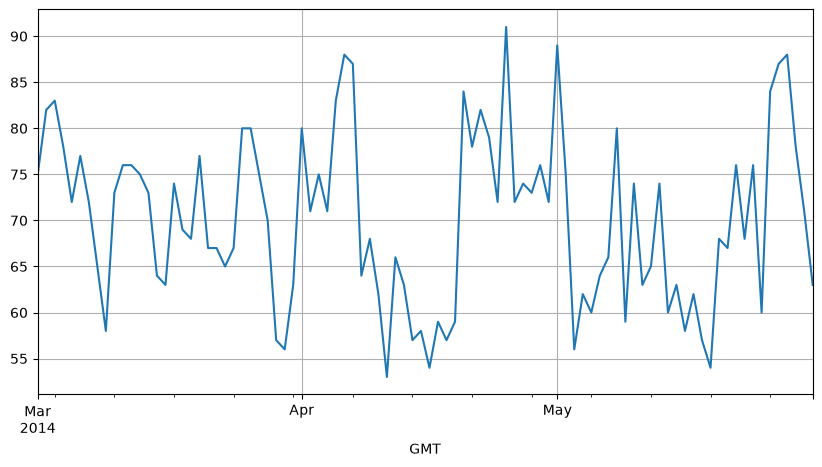

In [8]:
### Task 2: Plotting Mean Humidity During Spring (March to May)
from datetime import datetime
import pandas as pd

# 1. Ensure the GMT column is converted to datetime and set as the index (if not already done)
london['GMT'] = pd.to_datetime(london['GMT'])
london.index = london['GMT']
london = london.sort_index()

# 2. Define the date boundaries for the spring season in 2014 (March 1st to May 31st)
spring_start = datetime(2014, 3, 1)
spring_end = datetime(2014, 5, 31)

# 3. Slice the datetime-indexed DataFrame for the spring period and plot 'Mean Humidity'
london.loc[spring_start : spring_end]['Mean Humidity'].plot(grid=True, figsize=(10, 5))